# Lab 10 - K-Nearest Neighbours (KNN)

## Aim

To classify plots as high or not-high PMKSY priority with K-Nearest Neighbours, to
show why feature scaling matters for distance-based models, and to choose K with
cross-validation.

## Theory

KNN does not learn weights. To classify a new plot it:

1. Measures the distance from the new plot to every training plot, usually the
   **Euclidean distance** $d(a, b) = \sqrt{\sum_i (a_i - b_i)^2}$.
2. Takes the **K** closest plots (the neighbours).
3. Predicts the majority class among them (optionally giving closer neighbours a
   bigger vote: `weights="distance"`).

**Choosing K**

- **Small K** (e.g. 1): follows individual, possibly noisy, neighbours, so the model
  overfits (training accuracy near 100%).
- **Large K**: averages over many plots and smooths away real patterns (underfitting).

**Why scaling matters:** rainfall is measured in hundreds of mm while soil pH varies
by less than 3 units. Without scaling, distances are dominated by rainfall and the
other features are almost ignored.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv` (1,540 synthetic plots in 7 districts).

**Features (X)**

| Feature | Meaning |
|---|---|
| `soil_ph` | Soil acidity (pH) |
| `soil_organic_carbon` | Soil organic carbon (g/kg) |
| `groundwater_stress_pct` | How over-used the district's groundwater is (%) |
| `rainfall_mm_avg` | Average yearly rainfall of the district (mm) |
| `land_area_ha` | Size of the plot (hectares) |
| `claim_type` | IFR / CFR / CR, one-hot encoded (CFR is the reference category) |

**Target (y):** `pmksy_high` = 1 when `pmksy_score` is 65 or more (high priority for
the PMKSY irrigation scheme), otherwise 0. About 45% of plots are "high", so the two
classes are roughly balanced and accuracy is a fair first metric.

**Method:** an 80/20 stratified train/test split (`random_state=42`). Every choice of
hyper-parameter is made with **5-fold cross-validation on the training set only**;
the test set is used once, at the end, to report the final result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["soil_ph", "soil_organic_carbon", "groundwater_stress_pct",
            "rainfall_mm_avg", "land_area_ha"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = (df["pmksy_score"] >= 65).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Share of high-priority plots:", round(y.mean(), 3))
X.head()

Training samples: 1232 | Testing samples: 308
Share of high-priority plots: 0.455


,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,claim_CR,claim_IFR
0,7.1,17.22,58.0,1150.0,2.63,0,1
1,7.4,14.40,58.0,1150.0,1.25,0,1
2,7.4,14.40,58.0,1150.0,3.00,1,0
3,7.1,17.22,58.0,1150.0,3.59,0,1
4,7.1,17.22,58.0,1150.0,1.80,0,1


## Effect of Feature Scaling

The same KNN model (K = 15) is evaluated with 5-fold CV with and without
standardisation.

In [2]:
from sklearn.neighbors import KNeighborsClassifier

unscaled = cross_val_score(KNeighborsClassifier(n_neighbors=15), X_train, y_train, cv=cv).mean()
scaled = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
                         X_train, y_train, cv=cv).mean()

print(f"CV accuracy without scaling: {unscaled:.4f}")
print(f"CV accuracy with scaling:    {scaled:.4f}")
print()
print("Feature ranges (max - min):")
print((X_train.max() - X_train.min()).round(2).to_string())

CV accuracy without scaling: 0.8936
CV accuracy with scaling:    0.8969

Feature ranges (max - min):


soil_ph                      2.4
soil_organic_carbon         38.6
groundwater_stress_pct      35.0
rainfall_mm_avg           1250.0
land_area_ha                 3.8
claim_CR                     1.0
claim_IFR                    1.0


## Choosing K with Cross-Validation

For each K from 1 to 40 the scaled model is scored with 5-fold CV on the training set.
Training accuracy is shown too, to make the overfitting at small K visible.

Best K by CV: 25 | CV accuracy: 0.8985


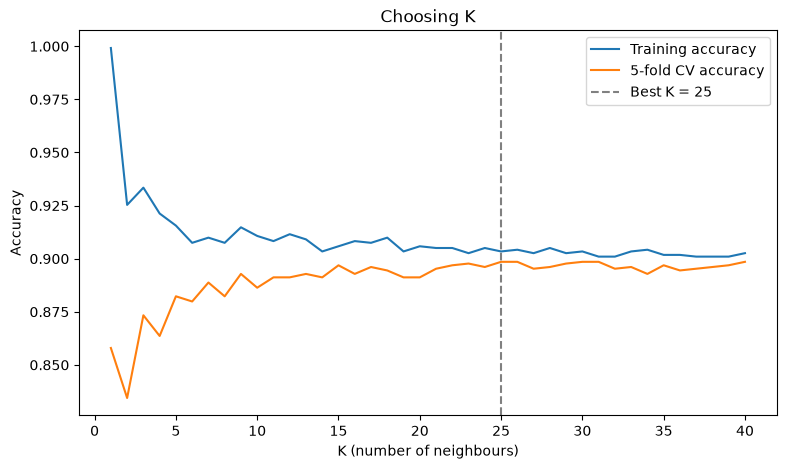

In [3]:
k_values = range(1, 41)
train_acc, cv_acc = [], []
for k in k_values:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=cv).mean())
    train_acc.append(m.fit(X_train, y_train).score(X_train, y_train))

best_k = list(k_values)[int(np.argmax(cv_acc))]
print("Best K by CV:", best_k, "| CV accuracy:", round(max(cv_acc), 4))

plt.figure(figsize=(9, 5))
plt.plot(k_values, train_acc, label="Training accuracy")
plt.plot(k_values, cv_acc, label="5-fold CV accuracy")
plt.axvline(best_k, color="grey", linestyle="--", label=f"Best K = {best_k}")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Choosing K")
plt.legend()
plt.show()

## Uniform vs Distance-Weighted Voting

In [4]:
for w in ["uniform", "distance"]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k, weights=w))
    print(f"weights='{w}': CV accuracy = {cross_val_score(m, X_train, y_train, cv=cv).mean():.4f}")

weights='uniform': CV accuracy = 0.8985
weights='distance': CV accuracy = 0.8904


## Final Model on the Test Set

Test accuracy: 0.9091

              precision    recall  f1-score   support

    Not high       0.97      0.86      0.91       168
        High       0.85      0.97      0.91       140

    accuracy                           0.91       308
   macro avg       0.91      0.91      0.91       308
weighted avg       0.92      0.91      0.91       308



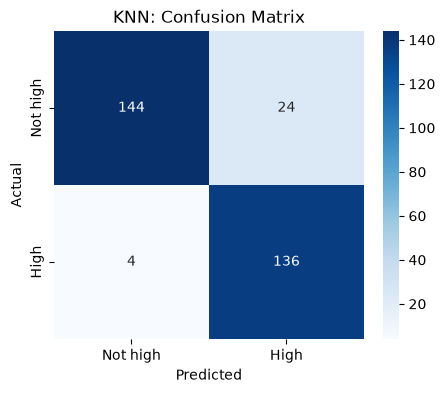

In [5]:
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Not high", "High"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not high", "High"], yticklabels=["Not high", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN: Confusion Matrix")
plt.show()

**How to read these metrics**

- **Accuracy**: share of all test plots classified correctly.
- **Precision (High)**: of the plots predicted "high", how many really are high.
- **Recall (High)**: of the truly high plots, how many the model caught.
- **F1**: the balance of precision and recall.
- **Confusion matrix**: rows are the true class, columns the predicted class. The
  diagonal holds correct predictions; the off-diagonal cells are the two kinds of mistake.

## Conclusion

K-Nearest Neighbours was used to classify plots as high or not-high PMKSY priority.

| Setting | 5-fold CV accuracy |
|---|---|
| K = 15, no scaling | 0.894 |
| K = 15, standardised | 0.897 |
| **K = 25, standardised (chosen)** | **0.899** |
| K = 25, distance-weighted votes | 0.890 |

Final test accuracy: **0.909** (precision 0.85, recall 0.97 for "High").

**Observations**

1. **Choosing K:** at K = 1 the training accuracy is 99.9% but the CV accuracy is only
   85.8%: the model memorises individual noisy plots (overfitting). CV accuracy rises
   with K and levels off at about 0.899 from K = 25 onwards; K = 25 was chosen as the
   first K that reaches it.
2. **Scaling:** standardising the features is the correct practice for KNN, because
   without it rainfall (range 1,250 mm) dominates the distance and soil pH (range 2.4)
   is almost ignored. In this dataset the gain is small (0.894 to 0.897) only because
   rainfall happens to be the single most important feature for PMKSY priority, so
   letting it dominate does little harm. On data where the important features have
   small ranges, skipping scaling would hurt much more.
3. **Uniform votes** worked slightly better than distance-weighted votes, because the
   labels contain random noise and giving the very closest neighbour extra weight
   follows that noise.
4. KNN reached the highest test accuracy of the classifiers in these labs, but it keeps
   the whole training set in memory and must compute distances to every plot for each
   prediction.
